# Shopping-Mall Evacuation: How Exit Width Must Scale with Crowd Size

This notebook simulates the evacuation of a simplified single-floor shopping mall (about 40 m × 30 m, with rectangular shop blocks and two exits) using the **Social Force Model**. Each shopper is an agent with its own desired walking speed. A driving force pushes them towards the nearest exit, and repulsive and contact forces from other people, walls and shop blocks push them away. Pedestrians follow a precomputed shortest-distance map, so they route around the shops. Their equations of motion are integrated with **Velocity-Verlet**, and **cell lists** find nearby pedestrians efficiently. Every scenario is repeated over many random seeds and reported with **95 % confidence intervals**. Sweeping exit width at crowd sizes from 100 to 400 people gives the minimum width that clears the floor within a 3-minute target, and shows whether that width must grow faster than occupancy.

**Key result:** *[to be completed in Section 5 — required exit width $w^*(N)$ and scaling exponent $\alpha$ with 95 % CIs]*

**Verification:** a single pedestrian's speed is checked against the analytic relaxation curve $v(t)=v_0\left(1-e^{-t/\tau}\right)$. The notebook also checks that people are conserved at every step, that results converge as the timestep shrinks (dt, dt/2, dt/4) while a too-large step goes unstable, and that exit flow is plausible against published bottleneck measurements (Section 5).

**How to run:** *Runtime → Run all* on a fresh Google Colab runtime, or *Run All* in a local Jupyter install. Missing packages are installed automatically in the first code cell. All random seeds are fixed and stated.

In [1]:
!pip install --upgrade pip

In [1]:
# Setup: install anything missing, then import.
# Works unchanged on a fresh Google Colab runtime and in a local Jupyter install.
import importlib.util, subprocess, sys

REQUIRED = ["numpy", "scipy", "matplotlib", "pandas", "numba"]
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import platform, time
import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numba
from numba import njit

# Reproducibility: every random draw in this notebook comes from a seeded generator.
SEED = 42
rng = np.random.default_rng(SEED)

# Run mode: QUICK_MODE uses fewer replications so "Run all" stays under ~10 minutes;
# set to False to regenerate the full study (more seeds per scenario).
QUICK_MODE = True

# Figures are saved to the repository's figures/ folder (or ./figures on Colab).
from pathlib import Path
FIG_DIR = Path("../figures") if Path("../figures").is_dir() else Path("figures")
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print(f"Python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"pandas {pd.__version__} | matplotlib {matplotlib.__version__} | numba {numba.__version__}")
print(f"SEED = {SEED} | QUICK_MODE = {QUICK_MODE}")

Python 3.14.3 | numpy 2.5.1 | scipy 1.18.1 | pandas 3.1.1 | matplotlib 3.11.1 | numba 0.68.1
SEED = 42 | QUICK_MODE = True


## 1. Problem and question

Large shopping malls in Colombo hold hundreds of shoppers on one open floor. In an emergency, everyone converges on a few exits at once, and the exits become bottlenecks: the floor can only empty as fast as people can pass through the doorways. If the exits are too narrow for the number of people inside, queues and crushing build up in front of them and evacuation takes much longer than the walking distance alone suggests.

**Question:** *How wide must the exits be to clear the floor within a target time of 3 minutes (180 s) as the number of occupants rises from 100 to 400?*

| Quantity | Symbol | Values studied |
|---|---|---|
| Number of occupants | $N$ | 100, 200, 300, 400 people |
| Width of each of the two exits | $w$ | swept over a range of widths (initially 1.0–3.0 m, refined by a pilot run in Section 5) |
| Evacuation time (last person out) | $T_\text{evac}$ | output, s, mean ± 95 % CI over seeds |
| Target evacuation time | $T_\text{target}$ | 180 s (assumed) |
| Required exit width | $w^*(N)$ | smallest $w$ with $T_\text{evac} \le T_\text{target}$ |

To see how the required width scales with occupancy, a power law $w^*(N) \propto N^{\alpha}$ is fitted. If $\alpha > 1$, exit width must grow **faster** than occupancy: doubling the number of people needs more than double the exit width. If $\alpha \approx 1$, width grows in proportion; if $\alpha < 1$, it grows more slowly.

**Why it matters:** exit width and the maximum safe occupancy are linked design decisions. Knowing how $w^*$ scales with $N$ shows whether an existing floor can safely hold more people, and how much wider the exits would need to be.

**Scope:** one floor with synthetic geometry. Model parameters come from the published Social Force Model literature. Everyone starts moving at $t = 0$ (no pre-movement delay). As a stretch scenario, one exit is blocked at the start of the emergency, and the increase in evacuation time and the peak crowd density at the remaining exit are measured.

## 2. Model, assumptions and equations

Full derivations and justifications are in `THEORY.md`. Reference numbers [n] refer to Section 7.

### 2.1 Geometry

The mall floor is the region $\Omega = [0, 40] \times [0, 30]$ m. It is bounded by walls and contains several rectangular shop blocks that people cannot walk through. There are **two exits of equal width $w$**, in the middle of the west wall and the middle of the east wall. A person counts as evacuated, and is removed, once they are 0.5 m outside an exit line.

### 2.2 Assumptions

1. **2D single floor; people are discs** of radius $r_i$, the standard Social Force Model representation [1], [2].
2. **Synthetic geometry** representing a medium-sized mall floor, since no real floor plan or evacuation data are available.
3. **No pre-movement time:** everyone starts moving at $t = 0$, so $T_\text{evac}$ is a movement time and the required widths are a lower bound.
4. **Nearest-exit routing:** each person follows the shortest walking route to the nearest exit and does not re-route to a less crowded exit. The layout is symmetric, so the two exits are loaded roughly equally.
5. **Homogeneous adults, normal (non-panic) walking.** Parameters come from [1], [2] and are assumed to transfer to local crowds.
6. **Target time** $T_\text{target} = 180$ s is assumed.

### 2.3 Equations of motion (Social Force Model)

For each pedestrian $i$ with position $\mathbf{x}_i$ (m), velocity $\mathbf{v}_i$ (m s⁻¹), mass $m_i$ (kg) and radius $r_i$ (m):

$$
\frac{d\mathbf{x}_i}{dt} = \mathbf{v}_i, \qquad
m_i \frac{d\mathbf{v}_i}{dt}
= m_i\,\frac{v_i^0\,\mathbf{e}_i^0(\mathbf{x}_i) - \mathbf{v}_i}{\tau}
+ \sum_{j \ne i} \mathbf{f}_{ij}
+ \sum_{W} \mathbf{f}_{iW}
$$

The first term is the **driving force**: each person relaxes towards their desired velocity over time $\tau$. The **pedestrian–pedestrian force** combines soft repulsion, body compression and sliding friction [2]:

$$
\mathbf{f}_{ij} = \Big[ A\, e^{(r_{ij} - d_{ij})/B} + k\, g(r_{ij} - d_{ij}) \Big]\,\mathbf{n}_{ij}
+ \kappa\, g(r_{ij} - d_{ij})\, \Delta v_{ji}^{t}\, \mathbf{t}_{ij}
$$

Here $d_{ij} = \lVert \mathbf{x}_i - \mathbf{x}_j \rVert$, $r_{ij} = r_i + r_j$, $\mathbf{n}_{ij} = (\mathbf{x}_i - \mathbf{x}_j)/d_{ij}$, $\mathbf{t}_{ij} = (-n_{ij,2}, n_{ij,1})$, $\Delta v^t_{ji} = (\mathbf{v}_j - \mathbf{v}_i)\cdot\mathbf{t}_{ij}$, and $g(x) = \max(x, 0)$. The $k$ and $\kappa$ terms therefore act only when the bodies overlap.

The **pedestrian–wall force** uses the closest point on each obstacle $W$: every outer wall segment, and every shop block taken as one rectangle (so a shop corner is not counted twice). The closest point is at distance $d_{iW}$, with normal $\mathbf{n}_{iW}$ and tangent $\mathbf{t}_{iW}$ [2]:

$$
\mathbf{f}_{iW} = \Big[ A\, e^{(r_i - d_{iW})/B} + k\, g(r_i - d_{iW}) \Big]\,\mathbf{n}_{iW}
- \kappa\, g(r_i - d_{iW})\, (\mathbf{v}_i \cdot \mathbf{t}_{iW})\, \mathbf{t}_{iW}
$$

Speeds are capped at $v_\text{max} = 1.3\,v_i^0$ [1].

### 2.4 Desired direction from a shortest-distance map

$D(\mathbf{x})$ is the shortest walking distance from $\mathbf{x}$ to the nearest exit. It approximately solves $\lVert \nabla D \rVert = 1$ with $D = 0$ at the exits and obstacles impassable. It is computed with the fast marching method [10] on a grid with spacing $h = 0.1$ m: nodes are accepted in order of increasing $D$, as in Dijkstra's algorithm [6], but each value comes from an upwind finite-difference solution of the eikonal equation, so routes are not bent towards the grid directions. Shop blocks are impassable. A band of width 0.35 m (the largest body radius) along every wall and shop edge costs 5 times as much to cross, so routes keep a body radius away from walls; because the band is passable, it cannot close even a narrow exit. The desired direction is

$$
\mathbf{e}_i^0 = -\frac{\nabla D(\mathbf{x}_i)}{\lVert \nabla D(\mathbf{x}_i) \rVert},
$$

so people route around shop blocks instead of walking into them.

### 2.5 Input model (random variates)

| Input | Distribution | Method | Source |
|---|---|---|---|
| Desired speed $v_i^0$ | $\mathcal{N}(1.34, 0.26^2)$ m/s, truncated to [0.56, 2.12] m/s (mean ± 3 s.d.) | rejection sampling | [1] |
| Body radius $r_i$ | $\mathcal{U}(0.25, 0.35)$ m | inverse transform | [2] |
| Start position | uniform on the free floor, no overlaps | random sequential placement with rejection | assumed |
| Start velocity | $\mathbf{0}$ | — | assumed |

### 2.6 Parameters

| Symbol | Meaning | Units | Value | Source |
|---|---|---|---|---|
| $m_i$ | mass | kg | 80 | [2] |
| $\tau$ | relaxation time | s | 0.5 | [2] |
| $A$ | repulsion strength | N | $2 \times 10^3$ | [2] |
| $B$ | repulsion range | m | 0.08 | [2] |
| $k$ | body-compression coefficient | kg s⁻² | $1.2 \times 10^5$ | [2] |
| $\kappa$ | sliding-friction coefficient | kg m⁻¹ s⁻¹ | $2.4 \times 10^5$ | [2] |
| $r_c$ | interaction cut-off, $2r_\text{max} + B\ln(A/1\,\text{N})$ | m | 1.3 | derived |
| $\Delta t$ | time step | s | 0.01 (checked in Section 4) | derived |
| $T_\text{max}$ | simulation time limit | s | 600 | assumed |
| $T_\text{target}$ | evacuation target | s | 180 | assumed |

### 2.7 Numerical method: Velocity-Verlet with a velocity predictor

$$
\begin{aligned}
\mathbf{x}_{n+1} &= \mathbf{x}_n + \mathbf{v}_n\,\Delta t + \tfrac12\,\mathbf{a}_n\,\Delta t^2 \\
\tilde{\mathbf{v}} &= \mathbf{v}_n + \mathbf{a}_n\,\Delta t \\
\mathbf{a}_{n+1} &= \mathbf{F}(\mathbf{x}_{n+1}, \tilde{\mathbf{v}}) / m \\
\mathbf{v}_{n+1} &= \mathbf{v}_n + \tfrac12\left(\mathbf{a}_n + \mathbf{a}_{n+1}\right)\Delta t
\end{aligned}
$$

The driving and friction forces depend on velocity, so plain Velocity-Verlet [3], [4] would be implicit. The Euler predictor $\tilde{\mathbf{v}}$ keeps the scheme explicit while staying **second-order accurate** (it is close to Heun's method, but $\mathbf{a}_{n+1}$ is reused as the next step's $\mathbf{a}_n$, so each step needs only one force evaluation; its error analysis is in Section 4). For one person in open space the model reduces to $\dot v = (v_0 - v)/\tau$, with exact solution $v(t) = v_0\left(1 - e^{-t/\tau}\right)$. This is the analytic check V1 in Section 4.

**Stability.** The stiffest time scale is body contact. Two overlapping people oscillate at $\omega = \sqrt{2(k + A/B)/m} \approx 60$ rad s⁻¹, so the step must satisfy $\omega\,\Delta t < 2$, i.e. $\Delta t < 0.033$ s. Sliding friction at a 2 cm overlap needs $\Delta t \lesssim 0.017$ s. The production step is $\Delta t = 0.01$ s.

**Neighbour search.** Forces are truncated at $r_c \approx 1.3$ m, where the repulsion is below 1 N (< 0.5 % of the driving force). Neighbours are found with **cell lists** of side $\ge r_c$ [5] (32 × 23 cells of 1.31 × 1.30 m), which reduces the cost per step from $O(N^2)$ to $O(N)$.

### 2.8 Outputs and statistics

For each run: the evacuation time $T_\text{evac}$ (last person out), $T_{90}$ (90 % out), the cumulative count $N_\text{out}(t)$, the specific exit flow $J_s = \Delta N_\text{out}/(w\,\Delta t)$ (persons m⁻¹ s⁻¹), and the peak density in front of each exit. Each scenario $(N, w)$ is repeated with $R$ independent seeds. The results are reported as

$$
\overline{T} \pm t_{0.975,\,R-1}\,\frac{s}{\sqrt{R}}
$$

(95 % CI) [9]. The required width $w^*(N)$ is the smallest $w$ whose **upper** 95 % limit is $\le T_\text{target}$, interpolated between the simulated widths. The scaling exponent $\alpha$ is fitted from $\log w^* = \log c + \alpha \log N$.

### 2.9 Concepts used

| Concept | Where it appears |
|---|---|
| **Particle-based simulation** | pedestrians as interacting particles with pair forces; cell-list neighbour search (2.3, 2.7) |
| **Numerical ODE solvers** | Newton's equations integrated with Velocity-Verlet / Heun; stability limit and convergence order (2.7, Section 4) |
| **Input modelling and random variate generation** | truncated-normal desired speeds, uniform radii, random non-overlapping start positions (2.5) |
| **Monte Carlo and the law of large numbers** | replications over seeds and 95 % confidence intervals on every result (2.8, Section 5) |

## 3. Implementation

### 3.1 Geometry

`make_mall(exit_width, blocked_exits=())` builds the floor described in Section 2.1:

- **Floor** 40 m × 30 m, bounded by four outer walls.
- **Six shop blocks** of 8 m × 5 m in two rows of three. The corridors are 4.0 m wide between shops in x and 6.67 m wide in y, so every corridor is at least 3 m wide.
- **Two exits** of width $w$, as gaps in the west and east walls, centred at $y = 15$ m. They open onto the central corridor, so no shop stands directly in front of an exit (the nearest shop is 4 m away). This also limits $w$ to at most 6.67 m.
- The layout is **symmetric** about both mid-lines, so under nearest-exit routing (assumption 4) each exit serves about half the crowd.

Walls are stored as line segments `[x1, y1, x2, y2]` (outer walls with the exit gaps cut out, plus the four edges of each shop), because the wall force in Section 2.3 uses the closest point on each segment. An exit named in `blocked_exits` is replaced by solid wall; this is used for the blocked-exit study. Each open exit also stores its outward normal, so "0.5 m outside the exit line" is the test $(\mathbf{x} - \mathbf{c}) \cdot \mathbf{n} > 0.5$ m. The cell ends with a few `assert` checks on the layout (corridor widths, gap width equal to $w$, shops inside the floor and clear of the exits).

In [2]:
# 3.1 Geometry: floor, shop blocks and exits.
from dataclasses import dataclass

FLOOR_W, FLOOR_H = 40.0, 30.0      # floor size (m)
SHOP_W, SHOP_H = 8.0, 5.0          # shop block size (m)
SHOP_COLS, SHOP_ROWS = 3, 2        # 3 x 2 grid of shops
EXIT_Y = FLOOR_H / 2               # both exits are centred on the floor's mid-line
EXIT_X = {"west": 0.0, "east": FLOOR_W}
EXIT_NORMAL = {"west": (-1.0, 0.0), "east": (1.0, 0.0)}   # outward unit normals


@dataclass(frozen=True)
class Mall:
    """Everything the simulation needs to know about one floor layout.

    All geometry is stored as plain float arrays so it can be passed straight
    into numba-compiled force code later.
    """
    walls: np.ndarray          # (M, 4) wall segments [x1, y1, x2, y2] (outer walls + shop edges)
    shops: np.ndarray          # (S, 4) shop rectangles [xmin, ymin, xmax, ymax]
    exit_names: tuple          # names of the OPEN exits, e.g. ("west", "east")
    exit_centres: np.ndarray   # (E, 2) centre of each open exit gap
    exit_normals: np.ndarray   # (E, 2) outward unit normal of each open exit
    exit_width: float          # width w of every exit (m)
    blocked: tuple             # names of exits closed off by a wall
    size: tuple = (FLOOR_W, FLOOR_H)


def make_mall(exit_width, blocked_exits=()):
    """Build the mall floor with two exits of width `exit_width` (m).

    Exits are gaps in the west and east walls, centred at y = 15 m. An exit named
    in `blocked_exits` is closed with a wall (used for the blocked-exit study).
    """
    blocked = tuple(blocked_exits)
    unknown = set(blocked) - set(EXIT_X)
    if unknown:
        raise ValueError(f"unknown exit(s) {sorted(unknown)}; choose from {sorted(EXIT_X)}")
    if len(set(blocked)) == len(EXIT_X):
        raise ValueError("at least one exit must stay open")

    # Shop blocks: equal corridors between shops and between shops and the walls.
    gap_x = (FLOOR_W - SHOP_COLS * SHOP_W) / (SHOP_COLS + 1)   # 4.0 m
    gap_y = (FLOOR_H - SHOP_ROWS * SHOP_H) / (SHOP_ROWS + 1)   # 6.67 m
    shops = np.array([[gap_x + c * (SHOP_W + gap_x), gap_y + r * (SHOP_H + gap_y),
                       gap_x + c * (SHOP_W + gap_x) + SHOP_W, gap_y + r * (SHOP_H + gap_y) + SHOP_H]
                      for r in range(SHOP_ROWS) for c in range(SHOP_COLS)])

    # The exit must fit inside the central corridor so no shop sits across it.
    if not 0.0 < exit_width <= gap_y:
        raise ValueError(f"exit_width must be in (0, {gap_y:.2f}] m, got {exit_width}")

    y_lo, y_hi = EXIT_Y - exit_width / 2, EXIT_Y + exit_width / 2
    walls = [[0.0, 0.0, FLOOR_W, 0.0],              # south
             [0.0, FLOOR_H, FLOOR_W, FLOOR_H]]      # north
    for name, x in EXIT_X.items():                  # west and east walls
        if name in blocked:
            walls.append([x, 0.0, x, FLOOR_H])      # solid wall, no gap
        else:
            walls += [[x, 0.0, x, y_lo], [x, y_hi, x, FLOOR_H]]   # wall with a gap of width w
    for x0, y0, x1, y1 in shops:                    # four edges of each shop block
        walls += [[x0, y0, x1, y0], [x1, y0, x1, y1], [x1, y1, x0, y1], [x0, y1, x0, y0]]

    open_exits = tuple(n for n in EXIT_X if n not in blocked)
    return Mall(walls=np.array(walls, dtype=float),
                shops=shops,
                exit_names=open_exits,
                exit_centres=np.array([[EXIT_X[n], EXIT_Y] for n in open_exits]),
                exit_normals=np.array([EXIT_NORMAL[n] for n in open_exits]),
                exit_width=float(exit_width),
                blocked=blocked)


def plot_mall(mall, ax=None, title=None):
    """Draw walls, shop blocks and exits (green = open, red = blocked)."""
    from matplotlib.patches import Rectangle
    ax = ax or plt.gca()
    for x0, y0, x1, y1 in mall.shops:
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc="0.85", ec="none", zorder=1))
    for x1, y1, x2, y2 in mall.walls:
        ax.plot([x1, x2], [y1, y2], color="k", lw=2, solid_capstyle="butt", zorder=2)
    w = mall.exit_width
    for name, x in EXIT_X.items():
        is_open = name in mall.exit_names
        ax.plot([x, x], [EXIT_Y - w / 2, EXIT_Y + w / 2], lw=6, zorder=3,
                color="tab:green" if is_open else "tab:red", alpha=0.6 if is_open else 1.0)
        ax.annotate(f"{name}\n{'open' if is_open else 'blocked'}", (x, EXIT_Y),
                    xytext=(-8 if name == "west" else 8, 0), textcoords="offset points",
                    ha="right" if name == "west" else "left", va="center", fontsize=8)
    ax.set_xlim(-6, FLOOR_W + 6)
    ax.set_ylim(-1, FLOOR_H + 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title(title or f"Mall floor, exit width w = {w:g} m")
    return ax


# Sanity checks on the layout (cheap, run every time).
_m = make_mall(1.5)
_gap_x = (FLOOR_W - SHOP_COLS * SHOP_W) / (SHOP_COLS + 1)
_gap_y = (FLOOR_H - SHOP_ROWS * SHOP_H) / (SHOP_ROWS + 1)
assert min(_gap_x, _gap_y) >= 3.0, "corridors must be at least 3 m wide"
assert len(_m.walls) == 2 + 4 + 4 * len(_m.shops)                 # two gapped side walls
assert len(make_mall(1.5, blocked_exits=("east",)).walls) == len(_m.walls) - 1
_seg_len = np.hypot(_m.walls[:, 2] - _m.walls[:, 0], _m.walls[:, 3] - _m.walls[:, 1])
_outer = 2 * (FLOOR_W + FLOOR_H)
assert np.isclose(_seg_len[:6].sum(), _outer - 2 * 1.5), "each exit gap must be exactly w wide"
assert np.all((_m.shops[:, [0, 1]] > 0) & (_m.shops[:, [2, 3]] < [FLOOR_W, FLOOR_H])), "shops inside floor"
# Nothing in the first 3 m in front of either exit.
assert _m.shops[:, 0].min() >= 3.0 and _m.shops[:, 2].max() <= FLOOR_W - 3.0
print(f"Geometry OK: {len(_m.shops)} shops, {len(_m.walls)} wall segments, "
      f"corridors {_gap_x:.2f} m (x) and {_gap_y:.2f} m (y), max exit width {_gap_y:.2f} m")

Geometry OK: 6 shops, 30 wall segments, corridors 4.00 m (x) and 6.67 m (y), max exit width 6.67 m


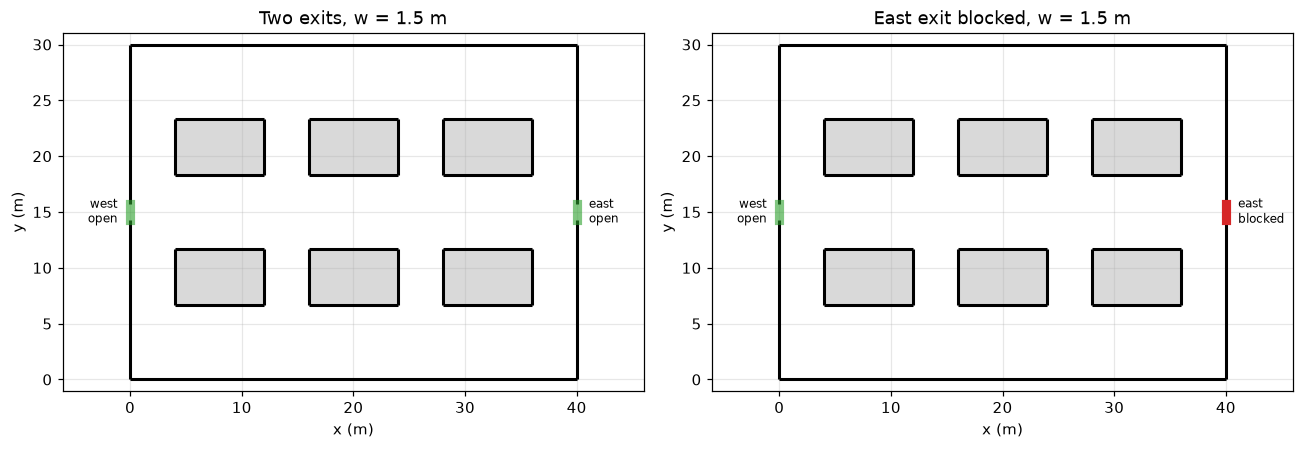

In [4]:
# Figure: the reference layout and the blocked-exit variant.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
plot_mall(make_mall(1.5), ax=axes[0], title="Two exits, w = 1.5 m")
plot_mall(make_mall(1.5, blocked_exits=("east",)), ax=axes[1], title="East exit blocked, w = 1.5 m")
fig.tight_layout()
fig.savefig(FIG_DIR / "mall_geometry.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.2 Distance map and desired direction

`make_distance_map(mall)` computes the walking distance $D(\mathbf{x})$ to the nearest open exit (Section 2.4) on a grid with $h = 0.1$ m, and from it the desired direction $\mathbf{e}^0 = -\nabla D / \lVert \nabla D \rVert$ at every grid node. `desired_direction(dmap, x, y)` reads $\mathbf{e}^0$ at any positions by bilinear interpolation.

Design choices:

- **Fast marching, not 8-connected Dijkstra.** A first version used Dijkstra on an 8-connected grid. Its distances are sums of grid steps, so its directions snap to multiples of 22.5°: next to the west wall it pointed 22.5° *into* the wall instead of along it, and the path-tracing check below failed. Fast marching solves $\lVert\nabla D\rVert = 1$ directly and removes this bias. Measured against the exact straight-line solution in the central corridor, the direction error is about 1–2° more than 6 m from an exit and up to about 14° within 3 m of it, where the first-order scheme is least accurate and where crowd forces dominate anyway.
- **A costly band instead of inflated obstacles.** Within 0.35 m of any wall or shop edge, each metre costs 5. Routes therefore keep clear of walls and corners, but $D$ is still defined where a person's centre can be (0.25–0.35 m from a wall), and no exit can be closed off, however narrow.
- **Targets trimmed to where a body fits.** The source nodes are the middle part of each exit line, $|y - 15| \le \max(w/2 - 0.35, 0)$ m, so people aim through the gap instead of at its edges.
- **Outside the floor** (past an exit), $\mathbf{e}^0$ is the exit's outward normal, so people keep walking until they are removed 0.5 m out.
- **On the ridge** where two exits are equally far ($x = 20$ m), $\nabla D$ can vanish; there a person heads straight for the nearest exit.
- The map depends only on the geometry, so it is computed **once per layout** (about 0.3 s), not once per time step.

The checks after the next cell confirm that every part of the floor can reach an exit, that $D$ is never shorter than the straight-line distance, that $D$ is symmetric when both exits are open, and that following $\mathbf{e}^0$ from 300 random start points always leads out through an open exit gap without entering a shop, for $w$ = 0.6, 1.5 and 3.0 m and with the east exit blocked.

In [3]:
# 3.2 Shortest-distance map D(x) and desired direction e0 = -grad D / |grad D|.
import heapq, math

GRID_H = 0.1          # grid spacing h (m)
GRID_MARGIN = 1.0     # grid extends this far outside the west/east walls (m), past the 0.5 m removal line
R_INFLATE = 0.35      # band along every wall and shop edge = largest body radius (m)
BAND_COST = 5.0       # crossing the band costs 5x normal walking, so routes keep a body radius off walls


@dataclass(frozen=True)
class DistanceMap:
    """Distance to the nearest open exit and the desired-direction field, on a regular grid.

    Arrays are indexed [j, i] with x = x0 + i*h and y = y0 + j*h.
    """
    x0: float
    y0: float
    h: float
    D: np.ndarray             # (ny, nx) walking distance to the nearest open exit (m); inf where impassable
    ex: np.ndarray            # (ny, nx) x-component of the unit desired direction (0 inside shops)
    ey: np.ndarray            # (ny, nx) y-component
    exit_centres: np.ndarray  # (E, 2) open exits, used as a fallback target


def _distance_to_shops(X, Y, shops):
    """Distance from each point to the nearest shop rectangle (0 inside or on its edge)."""
    d = np.full(np.shape(X), np.inf)
    for x0, y0, x1, y1 in shops:
        dx = np.maximum(np.maximum(x0 - X, X - x1), 0.0)
        dy = np.maximum(np.maximum(y0 - Y, Y - y1), 0.0)
        d = np.minimum(d, np.hypot(dx, dy))
    return d


def _distance_to_walls(X, Y, walls):
    """Distance from each point to the nearest wall segment (outer walls and shop edges)."""
    d = np.full(np.shape(X), np.inf)
    for x1, y1, x2, y2 in walls:
        sx, sy = x2 - x1, y2 - y1
        t = np.clip(((X - x1) * sx + (Y - y1) * sy) / (sx * sx + sy * sy), 0.0, 1.0)
        d = np.minimum(d, np.hypot(X - (x1 + t * sx), Y - (y1 + t * sy)))
    return d


def _fast_march(cost, sources, h):
    """First-order fast marching method for |grad T| = cost with T = 0 on the source nodes.

    Nodes are accepted in order of increasing T (like Dijkstra), but each new value comes from
    the upwind finite-difference solution of the eikonal equation instead of a sum of grid
    edges, so the result does not favour the grid's 4 or 8 directions. Returns inf where unreachable.
    """
    ny, nx = cost.shape
    NX = nx + 2                                   # pad with an impassable ring: no bounds checks
    c = np.pad(cost, 1, constant_values=np.inf).ravel().tolist()
    INF = math.inf
    T = [INF] * len(c)
    known = bytearray(len(c))
    heap = [(0.0, int(k)) for k in np.flatnonzero(np.pad(sources, 1))]
    for _, k in heap:
        T[k] = 0.0
    heapq.heapify(heap)
    while heap:
        _, k = heapq.heappop(heap)
        if known[k]:
            continue
        known[k] = 1
        for n in (k - 1, k + 1, k - NX, k + NX):
            if known[n] or c[n] == INF:
                continue
            a = min(T[n - 1] if known[n - 1] else INF, T[n + 1] if known[n + 1] else INF)
            b = min(T[n - NX] if known[n - NX] else INF, T[n + NX] if known[n + NX] else INF)
            if a > b:
                a, b = b, a
            f = c[n] * h
            t = 0.5 * (a + b + math.sqrt(2 * f * f - (b - a) ** 2)) if b - a < f else a + f
            if t < T[n]:
                T[n] = t
                heapq.heappush(heap, (t, n))
    return np.array(T).reshape(ny + 2, nx + 2)[1:-1, 1:-1]


def make_distance_map(mall, h=GRID_H):
    """Solve the eikonal equation from the open exits on a grid of the floor, then take -grad D."""
    W, H = mall.size
    eps = 1e-9
    nx = int(round((W + 2 * GRID_MARGIN) / h)) + 1
    ny = int(round(H / h)) + 1
    x0, y0 = -GRID_MARGIN, 0.0
    X, Y = np.meshgrid(x0 + h * np.arange(nx), y0 + h * np.arange(ny))

    # Cost per metre: 1 on open floor, BAND_COST within R_INFLATE of any wall or shop edge,
    # inf inside shops and outside the floor. The band is costly but passable, so it can never
    # close an exit, however narrow.
    on_floor = (X >= -eps) & (X <= W + eps)
    cost = np.where(_distance_to_walls(X, Y, mall.walls) < R_INFLATE, BAND_COST, 1.0)
    cost[(_distance_to_shops(X, Y, mall.shops) <= eps) | ~on_floor] = np.inf

    # Sources: nodes on each open exit line, trimmed by R_INFLATE at both ends so people aim
    # for the part of the gap their body fits through (at least the centre node is kept).
    half = max(mall.exit_width / 2 - R_INFLATE, 0.0)
    src = np.zeros((ny, nx), dtype=bool)
    for (cx, cy) in mall.exit_centres:
        src |= (np.abs(X - cx) < h / 2) & (np.abs(Y - cy) <= half + eps)
    D = _fast_march(cost, src, h)

    # Gradient by central differences, one-sided next to impassable nodes.
    Dn = np.where(np.isfinite(D), D, np.nan)

    def _grad(axis):
        diff = np.diff(Dn, axis=axis) / h
        pad = [(0, 0), (0, 0)]
        pad[axis] = (0, 1); fwd = np.pad(diff, pad, constant_values=np.nan)
        pad[axis] = (1, 0); bwd = np.pad(diff, pad, constant_values=np.nan)
        g = np.where(np.isnan(fwd), bwd, np.where(np.isnan(bwd), fwd, 0.5 * (fwd + bwd)))
        return np.nan_to_num(g, nan=0.0)

    gx, gy = _grad(1), _grad(0)
    norm = np.hypot(gx, gy)
    safe = np.where(norm > 0, norm, 1.0)
    ex, ey = np.where(norm > 0, -gx / safe, 0.0), np.where(norm > 0, -gy / safe, 0.0)
    # Outside the floor (past an exit) the desired direction is straight out.
    ex[X < -eps], ey[X < -eps] = -1.0, 0.0
    ex[X > W + eps], ey[X > W + eps] = 1.0, 0.0
    return DistanceMap(x0=x0, y0=y0, h=h, D=D, ex=ex, ey=ey, exit_centres=mall.exit_centres.copy())


def desired_direction(dmap, px, py):
    """Unit desired direction at points (px, py), by bilinear interpolation of the field.

    If the interpolated vector vanishes (e.g. exactly on the ridge between two exits),
    the person heads straight for the nearest open exit instead.
    """
    px, py = np.atleast_1d(np.asarray(px, float)), np.atleast_1d(np.asarray(py, float))
    ny, nx = dmap.D.shape
    fx, fy = (px - dmap.x0) / dmap.h, (py - dmap.y0) / dmap.h
    i = np.clip(np.floor(fx).astype(int), 0, nx - 2)
    j = np.clip(np.floor(fy).astype(int), 0, ny - 2)
    tx, ty = np.clip(fx - i, 0.0, 1.0), np.clip(fy - j, 0.0, 1.0)

    def lerp(F):
        return ((1 - tx) * (1 - ty) * F[j, i] + tx * (1 - ty) * F[j, i + 1]
                + (1 - tx) * ty * F[j + 1, i] + tx * ty * F[j + 1, i + 1])

    ex, ey = lerp(dmap.ex), lerp(dmap.ey)
    norm = np.hypot(ex, ey)
    stuck = norm < 1e-6
    if np.any(stuck):
        c = dmap.exit_centres
        dx, dy = c[:, 0][None, :] - px[stuck, None], c[:, 1][None, :] - py[stuck, None]
        k = np.argmin(np.hypot(dx, dy), axis=1)
        rows = np.arange(k.size)
        ex[stuck], ey[stuck] = dx[rows, k], dy[rows, k]
        norm[stuck] = np.hypot(ex[stuck], ey[stuck])
    return ex / norm, ey / norm


_t = time.perf_counter()
dmap_ref = make_distance_map(make_mall(1.5))
print(f"Distance map: grid {dmap_ref.D.shape[1]} x {dmap_ref.D.shape[0]} nodes, h = {GRID_H} m, "
      f"built in {time.perf_counter() - _t:.2f} s")

Distance map: grid 421 x 301 nodes, h = 0.1 m, built in 0.28 s


In [4]:
# Checks on the distance map and the direction field.

def trace_paths(dmap, starts, step=0.05, max_steps=2000):
    """Follow the desired-direction field from each start point with fixed steps (no physics).

    Returns an array (max_steps + 1, n, 2) of positions; a path is NaN after it leaves the grid
    0.5 m past an exit line.
    """
    W = FLOOR_W
    p = np.array(starts, dtype=float)
    out = np.full((max_steps + 1, len(p), 2), np.nan)
    out[0] = p
    active = np.ones(len(p), dtype=bool)
    for s in range(1, max_steps + 1):
        ex, ey = desired_direction(dmap, p[active, 0], p[active, 1])
        p[active] += step * np.column_stack([ex, ey])
        out[s, active] = p[active]
        active &= (p[:, 0] > -0.5) & (p[:, 0] < W + 0.5)
        if not active.any():
            break
    return out


def check_paths(mall, dmap, paths):
    """Every path must reach an open exit, pass through its gap, and never enter a shop."""
    W, H = mall.size
    w = mall.exit_width
    last = paths[np.isfinite(paths[..., 0]).sum(axis=0) - 1, np.arange(paths.shape[1])]
    assert np.all((last[:, 0] <= -0.5) | (last[:, 0] >= W + 0.5)), "some paths never reached an exit"
    for x0, y0, x1, y1 in mall.shops:
        inside = (paths[..., 0] > x0) & (paths[..., 0] < x1) & (paths[..., 1] > y0) & (paths[..., 1] < y1)
        assert not inside.any(), "a path entered a shop block"
    assert np.nanmin(paths[..., 1]) > 0 and np.nanmax(paths[..., 1]) < H, "a path crossed the north/south wall"
    # Where a path crosses x = 0 or x = W it must be inside an open exit gap.
    x = paths[..., 0]
    for side, xw in (("west", 0.0), ("east", W)):
        a, b = x[:-1], x[1:]
        cross = np.isfinite(a) & np.isfinite(b) & ((a - xw) * (b - xw) < 0)
        if cross.any():
            assert side in mall.exit_names, f"a path left through the blocked {side} exit"
            y_cross = paths[1:, :, 1][cross]
            assert np.all(np.abs(y_cross - EXIT_Y) < w / 2), f"a path crossed the {side} wall outside the gap"
    return last


_check_rng = np.random.default_rng(SEED)   # separate stream, so these checks do not shift later results
for w, blocked in [(0.6, ()), (1.5, ()), (3.0, ()), (1.5, ("east",))]:
    mall = make_mall(w, blocked_exits=blocked)
    dm = dmap_ref if (w, blocked) == (1.5, ()) else make_distance_map(mall)
    ny, nx = dm.D.shape
    X, Y = np.meshgrid(dm.x0 + dm.h * np.arange(nx), dm.y0 + dm.h * np.arange(ny))

    # (a) Every floor node outside the shops can reach an exit.
    walkable = (X >= 0) & (X <= FLOOR_W) & (_distance_to_shops(X, Y, mall.shops) > 1e-9)
    assert np.all(np.isfinite(dm.D[walkable])), "part of the floor cannot reach an exit"

    # (b) Grid distances are never shorter than the straight line to the nearest exit centre
    #     (allowing for the source segment, which is at most w/2 from the centre).
    c = mall.exit_centres
    euclid = np.min(np.hypot(X[..., None] - c[:, 0], Y[..., None] - c[:, 1]), axis=-1)
    assert np.all(dm.D[walkable] >= euclid[walkable] - w / 2 - 1e-9), "distance shorter than straight line"

    # (c) With two exits the layout is symmetric, so D must be too (mirror in x and in y).
    if not blocked:
        floor = dm.D[:, (X[0] >= 0) & (X[0] <= FLOOR_W)]
        assert np.allclose(floor, floor[:, ::-1], equal_nan=True), "D not mirror-symmetric in x"
        assert np.allclose(floor, floor[::-1, :], equal_nan=True), "D not mirror-symmetric in y"

    # (d) Following the field from 300 random start points (body centres >= 0.25 m from any shop)
    #     reaches an open exit through its gap without entering a shop.
    pts = np.column_stack([_check_rng.uniform(0.3, FLOOR_W - 0.3, 3000),
                           _check_rng.uniform(0.3, FLOOR_H - 0.3, 3000)])
    pts = pts[_distance_to_shops(pts[:, 0], pts[:, 1], mall.shops) >= 0.25][:300]
    last = check_paths(mall, dm, trace_paths(dm, pts))
    n_west = int(np.sum(last[:, 0] < 0))
    print(f"w = {w:3.1f} m, blocked = {', '.join(blocked) or 'none':<5}: all nodes reachable, D >= straight line, "
          f"300/300 paths exit through a gap (west {n_west}, east {300 - n_west})")

# (e) A point on the central corridor's axis, 10 m from the west exit, is exactly 10 m away.
_j, _i = int(round(EXIT_Y / GRID_H)), int(round((10.0 - dmap_ref.x0) / GRID_H))
assert abs(dmap_ref.D[_j, _i] - 10.0) < 1e-6, f"D = {dmap_ref.D[_j, _i]:.6f} m, expected 10 m"
print("Distance-map checks passed.")

w = 0.6 m, blocked = none : all nodes reachable, D >= straight line, 300/300 paths exit through a gap (west 148, east 152)
w = 1.5 m, blocked = none : all nodes reachable, D >= straight line, 300/300 paths exit through a gap (west 158, east 142)
w = 3.0 m, blocked = none : all nodes reachable, D >= straight line, 300/300 paths exit through a gap (west 144, east 156)
w = 1.5 m, blocked = east : all nodes reachable, D >= straight line, 300/300 paths exit through a gap (west 300, east 0)
Distance-map checks passed.


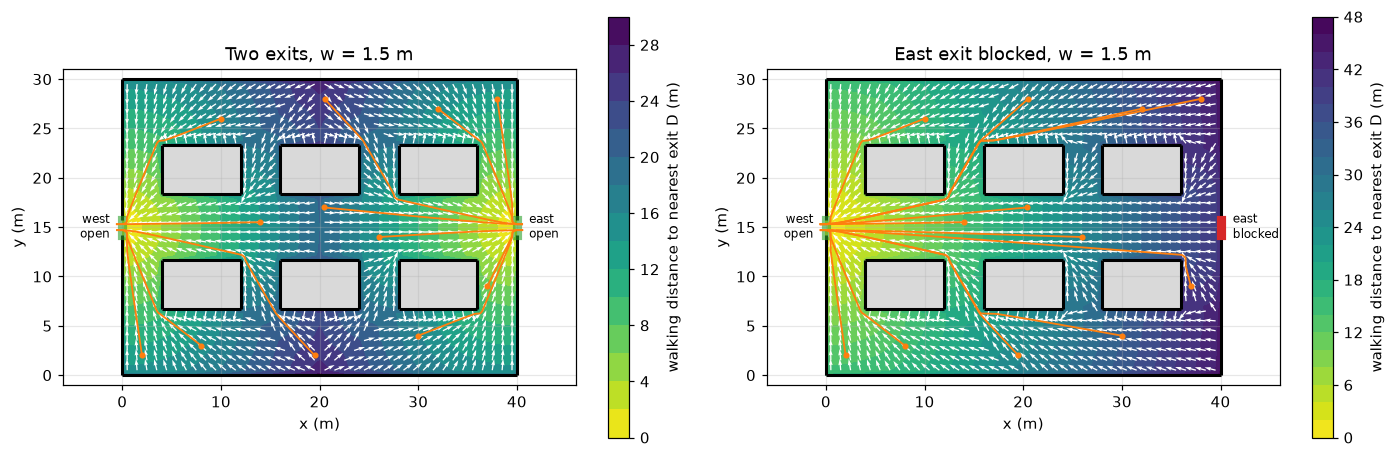

In [5]:
# Figure: distance map, desired directions and example routes.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
# Start points avoid x = 20 m exactly: that line is equidistant from both exits, so D has a ridge there.
_starts = np.array([[19.5, 2], [20.5, 28], [8, 3], [32, 27], [14, 15.5], [26, 14], [2, 2], [38, 28],
                    [10, 26], [30, 4], [20.4, 17], [37, 9]], dtype=float)
for ax, blocked in zip(axes, [(), ("east",)]):
    mall = make_mall(1.5, blocked_exits=blocked)
    dm = dmap_ref if not blocked else make_distance_map(mall)
    ny, nx = dm.D.shape
    xs, ys = dm.x0 + dm.h * np.arange(nx), dm.y0 + dm.h * np.arange(ny)
    Dplot = np.ma.masked_invalid(np.where((xs[None, :] >= 0) & (xs[None, :] <= FLOOR_W), dm.D, np.nan))
    cf = ax.contourf(xs, ys, Dplot, levels=np.arange(0, np.nanmax(Dplot.filled(np.nan)) + 2, 2),
                     cmap="viridis_r", zorder=0)
    k = 10   # one arrow per metre
    sel = np.s_[5::k, 15::k]
    U, V = dm.ex[sel], dm.ey[sel]
    show = (U ** 2 + V ** 2 > 0) & np.isfinite(dm.D[sel])
    Xq, Yq = np.meshgrid(xs[15::k], ys[5::k])
    ax.quiver(Xq[show], Yq[show], U[show], V[show], color="w", scale=45, width=0.0025, zorder=1)
    for path in np.moveaxis(trace_paths(dm, _starts), 1, 0):
        ax.plot(path[:, 0], path[:, 1], color="tab:orange", lw=1.2, zorder=4)
    ax.plot(_starts[:, 0], _starts[:, 1], "o", color="tab:orange", ms=3, zorder=4)
    plot_mall(mall, ax=ax, title=("Two exits" if not blocked else "East exit blocked") + ", w = 1.5 m")
    fig.colorbar(cf, ax=ax, shrink=0.85, label="walking distance to nearest exit D (m)")
fig.tight_layout()
fig.savefig(FIG_DIR / "distance_map.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Parameters and time integration

The parameters of Section 2.6 are defined once here, so every later cell uses the same values. `verlet_step` is the Velocity-Verlet scheme with a velocity predictor from Section 2.7. It takes the acceleration as a function `accel(x, v)`. Here that is only the driving force, for check V1. The crowd runs use `crowd_step` (Section 3.4), a compiled copy of the same scheme with the full force; check V1b shows that the two give identical results.

Each step evaluates the forces **once**: the acceleration computed at the new position and the predicted velocity is reused as $\mathbf{a}_n$ in the next step. The speed cap $v_\text{max} = 1.3\,v_i^0$ is applied after each velocity update.

In [6]:
# 3.3 Model parameters (Section 2.6) and the time integrator (Section 2.7).
MASS = 80.0          # m: body mass (kg)                                  [2]
TAU = 0.5            # tau: relaxation time (s)                           [2]
A_REP = 2.0e3        # A: repulsion strength (N)                          [2]
B_REP = 0.08         # B: repulsion range (m)                             [2]
K_BODY = 1.2e5       # k: body-compression coefficient (kg s^-2)          [2]
KAPPA = 2.4e5        # kappa: sliding-friction coefficient (kg m^-1 s^-1) [2]
R_CUT = 1.3          # r_c: interaction cut-off, centre to centre (m)     derived
V_MAX_FACTOR = 1.3   # v_max = 1.3 v0                                     [1]
DT = 0.01            # time step (s), checked in Section 4
T_MAX = 600.0        # simulation time limit (s)
T_TARGET = 180.0     # evacuation target (s)
# Input model (Section 2.5).
R_MIN, R_MAX = 0.25, 0.35   # body radius r_i ~ U(R_MIN, R_MAX) (m)                         [2]
V0_MEAN, V0_SD = 1.34, 0.26 # desired speed v0 ~ N(V0_MEAN, V0_SD^2), truncated at +-3 sd (m/s) [1]
REMOVE_DIST = 0.5           # a person is evacuated 0.5 m beyond an exit line (m)


def driving_acceleration(v, v0, e0, tau=TAU):
    """Driving force divided by mass, (v0 e0 - v) / tau, for every person.

    v: (N, 2) velocities, v0: (N,) desired speeds, e0: (N, 2) unit desired directions.
    """
    return (v0[:, None] * e0 - v) / tau


def cap_speed(v, v0, factor=V_MAX_FACTOR):
    """Scale down any velocity faster than v_max = factor * v0, keeping its direction."""
    speed = np.hypot(v[:, 0], v[:, 1])
    v_max = factor * v0
    scale = np.where(speed > v_max, v_max / np.maximum(speed, 1e-12), 1.0)
    return v * scale[:, None]


def verlet_step(x, v, a, dt, accel, v0):
    """One step of Velocity-Verlet with a velocity predictor (Section 2.7).

    accel(x, v) returns the (N, 2) accelerations. `a` is the acceleration returned by the
    previous step (or accel(x0, v0) at the start), so each step costs ONE force evaluation.
    Returns (x, v, a) at the new time.
    """
    x_new = x + v * dt + 0.5 * a * dt * dt      # position update
    v_pred = v + a * dt                         # Euler predictor, keeps the scheme explicit
    a_new = accel(x_new, v_pred)                # forces at the new position, predicted velocity
    v_new = v + 0.5 * (a + a_new) * dt          # trapezoidal velocity update
    return x_new, cap_speed(v_new, v0), a_new

### 3.4 Social forces and cell lists

The force code follows Section 2.3 term by term. It is compiled with numba because every run takes about $10^4$ time steps and the study needs hundreds of runs.

- **Pedestrian forces** (`pair_force`): the repulsion $A e^{(r_{ij}-d_{ij})/B}$, plus body compression $k\,g$ and sliding friction $\kappa\,g\,\Delta v^t_{ji}$ when the bodies overlap. Pairs more than $r_c = 1.3$ m apart are skipped.
- **Walls** (`wall_force`): each outer wall segment uses its closest point. Each **shop block is one obstacle**, using the closest point on its rectangle. If its four edges were separate walls, a person just off a corner would feel that corner twice, because both edges have the same closest point there.
- **Cell lists** (`build_cells`): the floor and the 1 m strips outside the exits are split into 32 × 23 cells of 1.31 × 1.30 m (each side $\ge r_c$). The cells are refilled by counting sort at every step. Each person looks only at the 3 × 3 block of cells around them, and people who have left are skipped. `crowd_accel(..., use_cells=False)` does the plain $O(N^2)$ sum; it is used only for check V3.
- **Time step** (`crowd_step`): the same Velocity-Verlet + predictor scheme as `verlet_step`, including the speed cap. Check V1b shows that the two agree to rounding error.
- The force parameters are passed in as an array (`model_params`) rather than read as globals: numba freezes globals at compile time, and the sensitivity study changes $\tau$.

In [7]:
# 3.4 Social forces, cell lists and the compiled time step (Sections 2.3 and 2.7).
# Everything inside the time loop is compiled with numba. The formulas are exactly those of Section 2.3.

# Cell grid: covers the floor plus the GRID_MARGIN strips outside the exits; every cell side >= R_CUT.
CELL_X0, CELL_Y0 = -GRID_MARGIN, 0.0
CELL_NX = int((FLOOR_W + 2 * GRID_MARGIN) // R_CUT)      # 32 columns
CELL_NY = int(FLOOR_H // R_CUT)                          # 23 rows
CELL_LX = (FLOOR_W + 2 * GRID_MARGIN) / CELL_NX          # 1.3125 m
CELL_LY = FLOOR_H / CELL_NY                              # 1.304 m
assert min(CELL_LX, CELL_LY) >= R_CUT, "cells must be at least as large as the cut-off"


def model_params(tau=TAU):
    """Pack the force parameters into one array for the compiled code (so none is frozen in by numba)."""
    return np.array([tau, A_REP, B_REP, K_BODY, KAPPA, R_CUT, V_MAX_FACTOR, MASS])


@njit(cache=False)
def field_direction(px, py, ex, ey, gx0, gy0, gh, exit_c):
    """Compiled version of desired_direction (Section 3.2) for one point: bilinear interpolation
    of the direction field, falling back to the nearest open exit centre where the field vanishes."""
    ny, nx = ex.shape
    fx, fy = (px - gx0) / gh, (py - gy0) / gh
    i = min(max(int(np.floor(fx)), 0), nx - 2)
    j = min(max(int(np.floor(fy)), 0), ny - 2)
    tx = min(max(fx - i, 0.0), 1.0)
    ty = min(max(fy - j, 0.0), 1.0)
    w00, w10, w01, w11 = (1 - tx) * (1 - ty), tx * (1 - ty), (1 - tx) * ty, tx * ty
    dx = w00 * ex[j, i] + w10 * ex[j, i + 1] + w01 * ex[j + 1, i] + w11 * ex[j + 1, i + 1]
    dy = w00 * ey[j, i] + w10 * ey[j, i + 1] + w01 * ey[j + 1, i] + w11 * ey[j + 1, i + 1]
    norm = np.hypot(dx, dy)
    if norm < 1e-6:
        best = np.inf
        for k in range(exit_c.shape[0]):
            cx, cy = exit_c[k, 0] - px, exit_c[k, 1] - py
            dd = np.hypot(cx, cy)
            if dd < best:
                best, dx, dy = dd, cx, cy
        norm = np.hypot(dx, dy)
    return dx / norm, dy / norm


@njit(cache=False)
def build_cells(x, alive):
    """Cell lists by counting sort: people in cell c are order[start[c]:start[c + 1]]."""
    n = x.shape[0]
    cell = np.full(n, -1, np.int64)
    count = np.zeros(CELL_NX * CELL_NY + 1, np.int64)
    for i in range(n):
        if alive[i]:
            cx = min(max(int(np.floor((x[i, 0] - CELL_X0) / CELL_LX)), 0), CELL_NX - 1)
            cy = min(max(int(np.floor((x[i, 1] - CELL_Y0) / CELL_LY)), 0), CELL_NY - 1)
            cell[i] = cy * CELL_NX + cx
            count[cell[i] + 1] += 1
    start = np.cumsum(count)
    order = np.empty(start[-1], np.int64)
    fill = start[:-1].copy()
    for i in range(n):
        if cell[i] >= 0:
            order[fill[cell[i]]] = i
            fill[cell[i]] += 1
    return cell, start, order


@njit(cache=False)
def pair_force(i, j, x, v, r, A, B, K, KAP, rc):
    """f_ij (N): soft repulsion + body compression along n_ij, sliding friction along t_ij."""
    dx, dy = x[i, 0] - x[j, 0], x[i, 1] - x[j, 1]
    d2 = dx * dx + dy * dy
    if d2 >= rc * rc or d2 == 0.0:
        return 0.0, 0.0
    d = np.sqrt(d2)
    nx, ny = dx / d, dy / d
    s = r[i] + r[j] - d                         # overlap r_ij - d_ij (negative when apart)
    f = A * np.exp(s / B)
    if s <= 0.0:
        return f * nx, f * ny
    f += K * s
    tx, ty = -ny, nx
    ft = KAP * s * ((v[j, 0] - v[i, 0]) * tx + (v[j, 1] - v[i, 1]) * ty)
    return f * nx + ft * tx, f * ny + ft * ty


@njit(cache=False)
def wall_force(d, nx, ny, vx, vy, ri, A, B, K, KAP):
    """f_iW (N) for a wall at distance d with unit normal (nx, ny) pointing towards the person."""
    s = ri - d
    f = A * np.exp(s / B)
    if s <= 0.0:
        return f * nx, f * ny
    f += K * s
    tx, ty = -ny, nx
    vt = vx * tx + vy * ty
    return f * nx - KAP * s * vt * tx, f * ny - KAP * s * vt * ty


@njit(cache=False)
def crowd_accel(x, v, r, v0, alive, walls, shops, ex, ey, gx0, gy0, gh, exit_c, prm, use_cells):
    """Acceleration of every person: driving force + pedestrian forces + wall and shop forces, / m.

    walls: (M, 4) outer wall segments. shops: (S, 4) rectangles, each treated as ONE obstacle
    (closest point on its boundary) so that a shop corner is not counted twice.
    use_cells=False sums over all pairs (O(N^2)); it is used only to verify the cell lists (V3).
    """
    tau, A, B, K, KAP, rc, mass = prm[0], prm[1], prm[2], prm[3], prm[4], prm[5], prm[7]
    n = x.shape[0]
    acc = np.zeros((n, 2))
    if use_cells:
        cell, start, order = build_cells(x, alive)
    for i in range(n):
        if not alive[i]:
            continue
        xi, yi, vxi, vyi, ri = x[i, 0], x[i, 1], v[i, 0], v[i, 1], r[i]
        fx, fy = 0.0, 0.0
        # Pedestrian-pedestrian forces.
        if use_cells:
            cx, cy = cell[i] % CELL_NX, cell[i] // CELL_NX
            for gy in range(max(cy - 1, 0), min(cy + 2, CELL_NY)):
                for gx in range(max(cx - 1, 0), min(cx + 2, CELL_NX)):
                    c = gy * CELL_NX + gx
                    for k in range(start[c], start[c + 1]):
                        j = order[k]
                        if j != i:
                            px, py = pair_force(i, j, x, v, r, A, B, K, KAP, rc)
                            fx += px
                            fy += py
        else:
            for j in range(n):
                if j != i and alive[j]:
                    px, py = pair_force(i, j, x, v, r, A, B, K, KAP, rc)
                    fx += px
                    fy += py
        # Outer walls: closest point on each segment.
        for w in range(walls.shape[0]):
            x1, y1, x2, y2 = walls[w, 0], walls[w, 1], walls[w, 2], walls[w, 3]
            sx, sy = x2 - x1, y2 - y1
            t = min(max(((xi - x1) * sx + (yi - y1) * sy) / (sx * sx + sy * sy), 0.0), 1.0)
            dx, dy = xi - (x1 + t * sx), yi - (y1 + t * sy)
            d = np.hypot(dx, dy)
            if 0.0 < d < rc:
                wx, wy = wall_force(d, dx / d, dy / d, vxi, vyi, ri, A, B, K, KAP)
                fx += wx
                fy += wy
        # Shop blocks: closest point on the rectangle's boundary.
        for s in range(shops.shape[0]):
            x0, y0, x1, y1 = shops[s, 0], shops[s, 1], shops[s, 2], shops[s, 3]
            qx, qy = min(max(xi, x0), x1), min(max(yi, y0), y1)
            dx, dy = xi - qx, yi - qy
            d = np.hypot(dx, dy)
            if d > 0.0:
                if d < rc:
                    wx, wy = wall_force(d, dx / d, dy / d, vxi, vyi, ri, A, B, K, KAP)
                    fx += wx
                    fy += wy
            else:
                # Centre inside the shop (only if something has gone badly wrong): push out through
                # the nearest edge, with the depth counted as extra overlap.
                dl, dr, db, dt_ = xi - x0, x1 - xi, yi - y0, y1 - yi
                m = min(dl, dr, db, dt_)
                nx, ny = (-1.0, 0.0) if m == dl else (1.0, 0.0) if m == dr else (0.0, -1.0) if m == db else (0.0, 1.0)
                wx, wy = wall_force(-m, nx, ny, vxi, vyi, ri, A, B, K, KAP)
                fx += wx
                fy += wy
        # Driving force, written directly as an acceleration (same expression as driving_acceleration).
        e0x, e0y = field_direction(xi, yi, ex, ey, gx0, gy0, gh, exit_c)
        acc[i, 0] = (v0[i] * e0x - vxi) / tau + fx / mass
        acc[i, 1] = (v0[i] * e0y - vyi) / tau + fy / mass
    return acc


@njit(cache=False)
def crowd_step(x, v, a, dt, r, v0, alive, walls, shops, ex, ey, gx0, gy0, gh, exit_c, prm, use_cells):
    """One step of the same Velocity-Verlet + predictor scheme as verlet_step (Section 3.3), compiled.

    V1b checks that it reproduces verlet_step exactly for a single pedestrian.
    """
    x_new = x + v * dt + 0.5 * a * dt * dt
    v_pred = v + a * dt
    a_new = crowd_accel(x_new, v_pred, r, v0, alive, walls, shops, ex, ey, gx0, gy0, gh, exit_c, prm, use_cells)
    v_new = v + 0.5 * (a + a_new) * dt
    vmax_factor = prm[6]
    for i in range(x.shape[0]):                  # speed cap v_max = 1.3 v0, as in cap_speed
        speed = np.hypot(v_new[i, 0], v_new[i, 1])
        vmax = vmax_factor * v0[i]
        if speed > vmax:
            scale = vmax / max(speed, 1e-12)
            v_new[i, 0] *= scale
            v_new[i, 1] *= scale
    return x_new, v_new, a_new

### 3.5 Initial crowd, exits and one evacuation run

`sample_crowd` draws the inputs of Section 2.5: radii by inverse transform, desired speeds from the truncated normal by rejection, and start positions by random sequential placement with rejection (no overlap with other people, shop blocks or walls). `simulate` runs the compiled time loop. After each step, anyone 0.5 m beyond an exit line is removed and their exit time is recorded. Every 0.5 s it records the number out through each exit and the density in a 2 m half-disc inside each exit. At **every** step it also checks conservation (V2) and that nobody has passed through a wall or a closed exit; a failure stops the run with an error. `run_evacuation(N, w, seed)` wraps all of this and returns $T_\text{evac}$, $T_{90}$ and the records.

**Seeds and common random numbers.** Replication $k$ uses seed $1000 + k$ in every scenario. The exit width does not change the free floor, so the same seed gives exactly the same starting crowd for every $w$. Different widths are therefore compared on identical crowds (common random numbers), which lowers the variance of the differences between them.

In [8]:
# 3.5 Initial crowd, exits and the evacuation run.
DENSITY_RADIUS = 2.0                                  # density is measured in a 2 m half-disc inside each exit
DENSITY_AREA = 0.5 * np.pi * DENSITY_RADIUS ** 2      # 6.28 m^2
REPLICATION_SEEDS = [1000 + k for k in range(40)]     # replication k uses seed 1000 + k in every scenario


def sample_crowd(n, mall, rng, v0_mean=V0_MEAN, v0_sd=V0_SD, max_tries=20_000):
    """Random variates of Section 2.5: radii, desired speeds and non-overlapping start positions.

    Radii: U(R_MIN, R_MAX). Desired speeds: N(v0_mean, v0_sd^2) truncated to mean +- 3 sd by
    rejection. Positions: random sequential placement, rejecting any point that overlaps a person
    already placed, a shop block or an outer wall. Exits do not change the free floor, so the same
    seed gives the same crowd for every exit width (common random numbers across widths).
    """
    W, H = mall.size
    r = rng.uniform(R_MIN, R_MAX, n)
    v0 = rng.normal(v0_mean, v0_sd, n)
    lo, hi = v0_mean - 3 * v0_sd, v0_mean + 3 * v0_sd
    bad = (v0 < lo) | (v0 > hi)
    while bad.any():                                   # rejection: redraw only the out-of-range values
        v0[bad] = rng.normal(v0_mean, v0_sd, bad.sum())
        bad = (v0 < lo) | (v0 > hi)
    x = np.empty((n, 2))
    for i in range(n):
        for _ in range(max_tries):
            p = rng.uniform([r[i], r[i]], [W - r[i], H - r[i]])
            if _distance_to_shops(p[0], p[1], mall.shops) < r[i]:
                continue
            if i and np.min(np.hypot(*(x[:i] - p).T) - r[:i]) < r[i]:
                continue
            x[i] = p
            break
        else:
            raise RuntimeError(f"could not place person {i} of {n} without overlap")
    return x, r, v0


@njit(cache=False)
def simulate(x, v, r, v0, walls, shops, ex, ey, gx0, gy0, gh, exit_c, exit_open, prm, dt, t_max,
             half_w, rec_every, snap_steps, use_cells):
    """Advance the crowd until everyone is out or t_max is reached (compiled).

    Checks at EVERY step (raising an error on failure):
      V2  n_inside + n_out == N;
      no NaN positions; nobody crosses the north/south walls; anyone outside the floor in x is
      inside an OPEN exit gap (so nobody passes through a wall or a blocked exit).
    Returns per-person exit time and exit (0 = west, 1 = east), the recording times, the cumulative
    count through each exit and the density in front of each exit (every rec_every steps and at the
    final step), snapshots, and the step count.
    """
    n = x.shape[0]
    x, v = x.copy(), v.copy()
    alive = np.ones(n, np.bool_)
    exit_time = np.full(n, np.nan)
    exit_side = np.full(n, -1, np.int64)
    n_side = np.zeros(2, np.int64)
    n_steps = int(round(t_max / dt))
    rec_out = np.zeros((n_steps // rec_every + 2, 2), np.int64)
    rec_dens = np.zeros((n_steps // rec_every + 2, 2))
    rec_t = np.zeros(n_steps // rec_every + 2)
    snaps = np.full((snap_steps.shape[0], n, 2), np.nan)
    a = crowd_accel(x, v, r, v0, alive, walls, shops, ex, ey, gx0, gy0, gh, exit_c, prm, use_cells)
    n_out, step, rec = 0, 0, 0
    while True:
        # Record (first and last step included) and take snapshots.
        done = n_out == n or step >= n_steps
        if step % rec_every == 0 or done:
            rec_t[rec] = step * dt
            rec_out[rec, 0], rec_out[rec, 1] = n_side[0], n_side[1]
            for i in range(n):
                if alive[i]:
                    for e in range(2):
                        ex_x = 0.0 if e == 0 else FLOOR_W
                        inside = x[i, 0] >= 0.0 if e == 0 else x[i, 0] <= FLOOR_W
                        if inside and np.hypot(x[i, 0] - ex_x, x[i, 1] - EXIT_Y) < DENSITY_RADIUS:
                            rec_dens[rec, e] += 1.0 / DENSITY_AREA
            rec += 1
        for s in range(snap_steps.shape[0]):
            if snap_steps[s] == step:
                for i in range(n):
                    if alive[i]:
                        snaps[s, i, 0], snaps[s, i, 1] = x[i, 0], x[i, 1]
        if done:
            break

        x, v, a = crowd_step(x, v, a, dt, r, v0, alive, walls, shops, ex, ey, gx0, gy0, gh, exit_c, prm, use_cells)
        step += 1

        # Remove anyone 0.5 m beyond an exit line.
        for i in range(n):
            if alive[i]:
                side = 0 if x[i, 0] < -REMOVE_DIST else 1 if x[i, 0] > FLOOR_W + REMOVE_DIST else -1
                if side >= 0:
                    alive[i] = False
                    exit_time[i], exit_side[i] = step * dt, side
                    n_side[side] += 1
                    n_out += 1
                    v[i, 0] = v[i, 1] = a[i, 0] = a[i, 1] = 0.0

        # Per-step checks.
        n_inside = 0
        for i in range(n):
            if alive[i]:
                n_inside += 1
                xi, yi = x[i, 0], x[i, 1]
                if not (np.isfinite(xi) and np.isfinite(yi)):
                    raise FloatingPointError("non-finite position: the integration has become unstable")
                if yi < 0.0 or yi > FLOOR_H:
                    raise AssertionError("a pedestrian crossed the north or south wall")
                if xi < 0.0 or xi > FLOOR_W:
                    e = 0 if xi < 0.0 else 1
                    if not exit_open[e] or abs(yi - EXIT_Y) > half_w + R_MAX:
                        raise AssertionError("a pedestrian left the floor outside an open exit gap")
        if n_inside + n_out != n:
            raise AssertionError("V2 failed: n_inside + n_out != N")
    return exit_time, exit_side, rec_t[:rec], rec_out[:rec], rec_dens[:rec], snaps, step


_MALL_CACHE, _DMAP_CACHE = {}, {}


def get_mall(w, blocked=()):
    """Mall and distance map for exit width w (cached: the fast marching map takes ~0.2 s)."""
    key = (round(float(w), 9), tuple(sorted(blocked)))
    if key not in _MALL_CACHE:
        _MALL_CACHE[key] = make_mall(w, blocked_exits=blocked)
        _DMAP_CACHE[key] = make_distance_map(_MALL_CACHE[key])
    return _MALL_CACHE[key], _DMAP_CACHE[key]


def outer_walls(mall):
    """The outer wall segments (make_mall appends the four edges of every shop after them)."""
    return mall.walls[: len(mall.walls) - 4 * len(mall.shops)]


@dataclass
class RunResult:
    n: int
    w: float
    seed: int
    blocked: tuple
    t_evac: float          # time the last person leaves (s); NaN if the run did not clear by t_max
    t_90: float            # time 90 % have left (s); NaN if fewer than 90 % left
    cleared: bool
    n_west: int            # people out through each exit
    n_east: int
    r: np.ndarray          # (N,) body radii (m)
    v0: np.ndarray         # (N,) desired speeds (m/s)
    exit_time: np.ndarray  # (N,) exit time of each person (NaN if still inside)
    exit_side: np.ndarray  # (N,) 0 = west, 1 = east, -1 = still inside
    t_rec: np.ndarray      # recording times (s)
    n_out_rec: np.ndarray  # (n_rec, 2) cumulative number out through west / east
    density_rec: np.ndarray  # (n_rec, 2) people per m^2 in the half-disc inside each exit
    snaps: np.ndarray      # (n_snap, N, 2) positions at snap_times (NaN once evacuated)
    snap_times: tuple
    wall_s: float          # wall-clock time of the run (s)


def run_evacuation(n, w, seed, blocked=(), dt=DT, t_max=T_MAX, tau=TAU, v0_mean=V0_MEAN,
                   snap_times=(), rec_dt=0.5, use_cells=True):
    """One evacuation run: sample a crowd with `seed`, simulate it, return a RunResult."""
    mall, dm = get_mall(w, blocked)
    rng = np.random.default_rng(seed)
    x, r, v0 = sample_crowd(n, mall, rng, v0_mean=v0_mean)
    exit_open = np.array(["west" in mall.exit_names, "east" in mall.exit_names])
    rec_every = max(1, int(round(rec_dt / dt)))
    snap_steps = np.array([int(round(t / dt)) for t in snap_times], dtype=np.int64)
    t0 = time.perf_counter()
    exit_time, exit_side, t_rec, n_out_rec, dens, snaps, steps = simulate(
        x, np.zeros_like(x), r, v0, outer_walls(mall), mall.shops, dm.ex, dm.ey, dm.x0, dm.y0, dm.h,
        mall.exit_centres, exit_open, model_params(tau), dt, t_max, w / 2, rec_every, snap_steps, use_cells)
    wall_s = time.perf_counter() - t0
    out = np.isfinite(exit_time)
    # V2 again, on the returned data, and X3: nobody leaves through a blocked exit.
    assert out.sum() + (~out).sum() == n and np.array_equal(out, exit_side >= 0)
    assert all(exit_open[s] for s in np.unique(exit_side[out])), "someone left through a blocked exit"
    k90 = int(np.ceil(0.9 * n))
    times = np.sort(exit_time[out])
    return RunResult(n=n, w=float(w), seed=int(seed), blocked=tuple(blocked),
                     t_evac=float(times[-1]) if out.all() else np.nan,
                     t_90=float(times[k90 - 1]) if out.sum() >= k90 else np.nan,
                     cleared=bool(out.all()), n_west=int((exit_side == 0).sum()), n_east=int((exit_side == 1).sum()),
                     r=r, v0=v0, exit_time=exit_time, exit_side=exit_side, t_rec=t_rec,
                     n_out_rec=n_out_rec, density_rec=dens, snaps=snaps, snap_times=tuple(snap_times), wall_s=wall_s)


def mean_ci(values, level=0.95):
    """Sample mean and half-width of the t-based confidence interval (Section 2.8)."""
    from scipy import stats
    v = np.asarray(values, float)
    half = stats.t.ppf(0.5 + level / 2, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean(), half

In [9]:
# Cost of one run. The first call compiles the numba functions (a few seconds, once per session).
_t = time.perf_counter()
run_evacuation(20, 1.5, REPLICATION_SEEDS[0], t_max=1.0)
print(f"numba compilation: {time.perf_counter() - _t:.1f} s (once)")
for _n in (100, 400):
    _res = run_evacuation(_n, 1.5, REPLICATION_SEEDS[0])
    _steps = int(round(_res.t_evac / DT))
    print(f"N = {_n:3d}, w = 1.5 m: T_evac = {_res.t_evac:6.2f} s simulated in {_res.wall_s:5.2f} s of compute "
          f"({_steps} steps, {1e6 * _res.wall_s / _steps:5.1f} us per step)")

numba compilation: 5.1 s (once)
N = 100, w = 1.5 m: T_evac =  39.04 s simulated in  0.06 s of compute (3904 steps,  14.2 us per step)
N = 400, w = 1.5 m: T_evac =  93.56 s simulated in  0.91 s of compute (9356 steps,  97.4 us per step)


## 4. Verification

Every check is an `assert` or tolerance test, so "Run all" stops if one fails. V1–V3 are below. V4–V6 (time-step convergence, stability limit and exit-flow plausibility) are added with the experiments.

### V1: single pedestrian, analytic relaxation

One person starts from rest in open space with a fixed desired direction, so only the driving force acts and the motion reduces to $\dot v = (v_0 - v)/\tau$. The exact solution is $v(t) = v_0\left(1 - e^{-t/\tau}\right)$, $x(t) = v_0\left[t - \tau\left(1 - e^{-t/\tau}\right)\right]$. This tests the integrator, the sign of the driving term, $\tau$ and the units, using the same `verlet_step` as the crowd simulation.

**Expected error.** On this equation, with $z = -\Delta t/\tau$, the scheme multiplies the error by the main root of $\lambda^2 - \left(1 + \tfrac32 z\right)\lambda + \tfrac12 z = 0$ each step, which is $\lambda = 1 + z + \tfrac12 z^2 - \tfrac14 z^3 + O(z^4)$. (The second root is about $z/2$ and dies out immediately.) $\lambda$ matches $e^{z}$ up to $z^2$, so the method is **second order**, with local error $\tfrac{5}{12}|z|^3$ per step (Heun's method would have $\tfrac16|z|^3$). Accumulated over the run, the speed error peaks at $t = \tau$ at about

$$
v_0 \left(\frac{\Delta t}{\tau}\right)^2 \frac{5}{12\,e} \approx 8.2 \times 10^{-5}\ \text{m/s} \quad \text{for } \Delta t = 0.01 \text{ s}.
$$

**Pass criterion.** The maximum speed error (m/s) and position error (m) over 5 s ($10\tau$) must both be below $10^{-3}$. This is about 12 times the expected error, but tight enough that a first-order method fails it: explicit Euler, with expected error $v_0(\Delta t/\tau)/(2e) \approx 4.9 \times 10^{-3}$ m/s, is run alongside as a negative control.

V1 PASS: dt = 0.01 s, max |v - v_exact| = 8.21e-05 m/s, max |x - x_exact| = 6.69e-05 m (tolerance 1e-03)
     For comparison, explicit Euler at the same dt: max speed error 4.97e-03 m/s (fails, as it should)


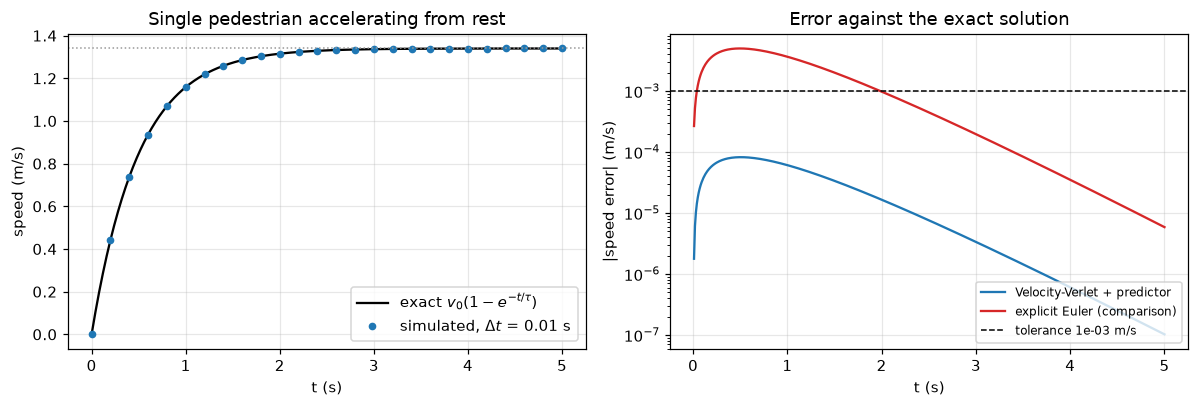

In [10]:
# V1: one pedestrian from rest in open space vs the analytic relaxation v(t) = v0 (1 - exp(-t/tau)).
V1_V0, V1_T_END, V1_TOL = 1.34, 5.0, 1e-3       # desired speed (m/s), duration = 10 tau (s), tolerance (m/s)
_v0 = np.array([V1_V0])
_e0 = np.array([[1.0, 0.0]])                     # fixed direction: no walls, no other people


def _accel_free(x, v):
    return driving_acceleration(v, _v0, _e0)


def relaxation_run(dt, scheme="verlet", t_end=V1_T_END):
    """Speed and distance walked over time for one pedestrian starting from rest."""
    n = int(round(t_end / dt))
    x, v = np.zeros((1, 2)), np.zeros((1, 2))
    a = _accel_free(x, v)
    speed, dist = np.zeros(n + 1), np.zeros(n + 1)
    for k in range(1, n + 1):
        if scheme == "verlet":
            x, v, a = verlet_step(x, v, a, dt, _accel_free, _v0)
        else:                                    # explicit Euler, for comparison only
            x, v = x + v * dt, v + _accel_free(x, v) * dt
        speed[k], dist[k] = np.hypot(*v[0]), np.hypot(*x[0])
    return dt * np.arange(n + 1), speed, dist


def relaxation_exact(t, v0=V1_V0, tau=TAU):
    """Exact speed and distance: v = v0 (1 - e^(-t/tau)), x = v0 (t - tau (1 - e^(-t/tau)))."""
    return v0 * (1 - np.exp(-t / tau)), v0 * (t - tau * (1 - np.exp(-t / tau)))


t1, s_vv, x_vv = relaxation_run(DT)
s_ex, x_ex = relaxation_exact(t1)
err_v, err_x = np.max(np.abs(s_vv - s_ex)), np.max(np.abs(x_vv - x_ex))
assert err_v < V1_TOL, f"V1 failed: max speed error {err_v:.2e} m/s >= {V1_TOL:.0e} m/s"
assert err_x < V1_TOL, f"V1 failed: max position error {err_x:.2e} m >= {V1_TOL:.0e} m"
print(f"V1 PASS: dt = {DT} s, max |v - v_exact| = {err_v:.2e} m/s, max |x - x_exact| = {err_x:.2e} m "
      f"(tolerance {V1_TOL:.0e})")

# The tolerance is strict enough to reject a first-order method: explicit Euler fails it.
_, s_eu, _ = relaxation_run(DT, scheme="euler")
err_eu = np.max(np.abs(s_eu - s_ex))
assert err_eu > V1_TOL, "tolerance too loose: it would not detect a first-order integrator"
print(f"     For comparison, explicit Euler at the same dt: max speed error {err_eu:.2e} m/s (fails, as it should)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(t1, s_ex, "k-", lw=1.5, label=r"exact $v_0(1-e^{-t/\tau})$")
axes[0].plot(t1[::20], s_vv[::20], "o", ms=4, color="tab:blue", label=f"simulated, $\\Delta t$ = {DT} s")
axes[0].axhline(V1_V0, color="0.6", ls=":", lw=1)
axes[0].set(xlabel="t (s)", ylabel="speed (m/s)", title="Single pedestrian accelerating from rest")
axes[0].legend(loc="lower right")
axes[1].semilogy(t1[1:], np.abs(s_vv - s_ex)[1:], color="tab:blue", label="Velocity-Verlet + predictor")
axes[1].semilogy(t1[1:], np.abs(s_eu - s_ex)[1:], color="tab:red", label="explicit Euler (comparison)")
axes[1].axhline(V1_TOL, color="k", ls="--", lw=1, label=f"tolerance {V1_TOL:.0e} m/s")
axes[1].set(xlabel="t (s)", ylabel="|speed error| (m/s)", title="Error against the exact solution")
axes[1].legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "verification_relaxation.png", dpi=150, bbox_inches="tight")
plt.show()

### V1b: the compiled crowd code matches the tested Python code

The crowd runs use the compiled `crowd_step` and `field_direction`, not the Python `verlet_step` and `desired_direction` tested by V1 and Section 3.2. This check runs both versions side by side, for one pedestrian over 5 s and for the direction field at 5000 random points. They must agree to $10^{-12}$.

In [11]:
# V1b: the compiled crowd code reproduces the Python code that V1 and Section 3.2 tested.
# (a) crowd_step = verlet_step for one pedestrian with a uniform desired direction (1, 0), no walls.
_no_walls = np.zeros((0, 4))
_field = (np.ones((2, 2)), np.zeros((2, 2)), -100.0, -100.0, 1000.0, np.array([[0.0, 15.0]]))  # e0 = (1, 0)
_one = dict(r=np.array([0.3]), v0=_v0, alive=np.ones(1, np.bool_))
_xc, _vc = np.array([[5.0, 15.0]]), np.zeros((1, 2))
_ac = crowd_accel(_xc, _vc, _one["r"], _v0, _one["alive"], _no_walls, _no_walls, *_field, model_params(), True)
_xp, _vp = _xc.copy(), _vc.copy()
_ap = _accel_free(_xp, _vp)
_diff = 0.0
for _ in range(int(round(V1_T_END / DT))):
    _xc, _vc, _ac = crowd_step(_xc, _vc, _ac, DT, _one["r"], _v0, _one["alive"], _no_walls, _no_walls,
                               *_field, model_params(), True)
    _xp, _vp, _ap = verlet_step(_xp, _vp, _ap, DT, _accel_free, _v0)
    _diff = max(_diff, np.abs(_xc - _xp).max(), np.abs(_vc - _vp).max())
assert _diff < 1e-12, f"compiled step differs from verlet_step by {_diff:.2e}"

# (b) field_direction (compiled) = desired_direction (Python) at 5000 random points.
_mall, _dm = get_mall(1.5)
_chk = np.random.default_rng(SEED + 1)
_P = np.column_stack([_chk.uniform(-GRID_MARGIN, FLOOR_W + GRID_MARGIN, 5000), _chk.uniform(0, FLOOR_H, 5000)])
_e_py = np.column_stack(desired_direction(_dm, _P[:, 0], _P[:, 1]))
_e_nb = np.array([field_direction(px, py, _dm.ex, _dm.ey, _dm.x0, _dm.y0, _dm.h, _dm.exit_centres) for px, py in _P])
assert np.allclose(_e_nb, _e_py, rtol=0, atol=1e-12), "compiled direction lookup differs"
print(f"V1b PASS: compiled step vs verlet_step over {V1_T_END:g} s: max difference {_diff:.1e}; "
      f"compiled vs Python direction field at 5000 points: max difference {np.abs(_e_nb - _e_py).max():.1e}")

V1b PASS: compiled step vs verlet_step over 5 s: max difference 0.0e+00; compiled vs Python direction field at 5000 points: max difference 0.0e+00


### V2: conservation of people

$N_\text{inside} + N_\text{out} = N$ must hold at every step of every run. The check is built into `simulate`, so it runs in every simulation in this notebook. Two more checks run alongside it: no position becomes non-finite, and nobody leaves the floor except through an open exit. The cell below also checks the returned records of a two-exit run and a blocked-exit run.

In [12]:
# V2: conservation. simulate() raises an error at any step where n_inside + n_out != N, a position is
# not finite, or someone is outside the floor anywhere other than an open exit gap. Every run in this
# notebook therefore passes V2 at every step, or "Run all" stops. Here the returned records are also checked.
for _n, _blocked in [(400, ()), (200, ("east",))]:
    _res = run_evacuation(_n, 1.5, REPLICATION_SEEDS[0], blocked=_blocked)
    _total = _res.n_out_rec.sum(axis=1)
    assert _res.cleared and _total[0] == 0 and _total[-1] == _n, "everyone must leave, and only once"
    assert np.all(np.diff(_total) >= 0), "the number evacuated can never fall"
    assert _res.n_west + _res.n_east == _n == np.isfinite(_res.exit_time).sum()
    if _blocked:
        assert _res.n_east == 0, "nobody may leave through the blocked exit"
    print(f"V2 PASS: N = {_n}, blocked = {', '.join(_blocked) or 'none':<4}: n_inside + n_out = N at all "
          f"{int(round(_res.t_evac / DT))} steps; out through west {_res.n_west}, east {_res.n_east}")

V2 PASS: N = 400, blocked = none: n_inside + n_out = N at all 9356 steps; out through west 215, east 185
V2 PASS: N = 200, blocked = east: n_inside + n_out = N at all 8862 steps; out through west 200, east 0


### V3: cell lists give the same forces as the brute-force sum

The cell lists must find every pair closer than $r_c$. Two random crowds are tested, each with 10 % of people marked as already evacuated:

- a dense patch of about 2 people/m², with many overlapping bodies, so every force term is active;
- a crowd spread over the whole grid, including the strips outside the exits where cell indices are clamped.

The accelerations from the cell lists and from the $O(N^2)$ sum must agree to a relative tolerance of $10^{-10}$; only the order of summation differs.

In [13]:
# V3: forces from the cell lists equal the brute-force O(N^2) sum (same cut-off) on random crowds.
_mall, _dm = get_mall(1.5)
_chk = np.random.default_rng(SEED + 2)
for _label, _box in [("dense patch", (2.0, 22.0, 10.0, 20.0)),            # ~2 people/m^2, many overlaps
                     ("whole floor and exit strips", (-GRID_MARGIN, FLOOR_W + GRID_MARGIN, 0.0, FLOOR_H))]:
    _pts = np.column_stack([_chk.uniform(_box[0], _box[1], 4000), _chk.uniform(_box[2], _box[3], 4000)])
    _xs = _pts[_distance_to_shops(_pts[:, 0], _pts[:, 1], _mall.shops) > 0][:400]   # not inside a shop
    _n = len(_xs)
    _vs, _rs = _chk.normal(0, 1, (_n, 2)), _chk.uniform(R_MIN, R_MAX, _n)
    _v0s, _alive = _chk.uniform(0.8, 1.8, _n), _chk.random(_n) > 0.1         # 10 % already evacuated
    _args = (_xs, _vs, _rs, _v0s, _alive, outer_walls(_mall), _mall.shops, _dm.ex, _dm.ey, _dm.x0, _dm.y0,
             _dm.h, _mall.exit_centres, model_params())
    _a_cell, _a_brute = crowd_accel(*_args, True), crowd_accel(*_args, False)
    np.testing.assert_allclose(_a_cell, _a_brute, rtol=1e-10, atol=1e-10)
    assert np.all(_a_cell[~_alive] == 0), "evacuated people must feel no force"
    _d = np.hypot(*(_xs[_alive, None] - _xs[None, _alive]).transpose(2, 0, 1))
    _iu = np.triu_indices(_alive.sum(), 1)
    _n_pairs = int((_d[_iu] < R_CUT).sum())
    _n_overlap = int((_d[_iu] < (_rs[_alive, None] + _rs[None, _alive])[_iu]).sum())
    print(f"V3 PASS ({_label}): {_n_pairs} interacting pairs, {_n_overlap} overlapping; "
          f"max |a_cell - a_brute| = {np.abs(_a_cell - _a_brute).max():.1e} m/s^2 "
          f"(max |a| = {np.abs(_a_brute).max():.1e} m/s^2)")

V3 PASS (dense patch): 1899 interacting pairs, 433 overlapping; max |a_cell - a_brute| = 7.3e-12 m/s^2 (max |a| = 5.3e+04 m/s^2)
V3 PASS (whole floor and exit strips): 296 interacting pairs, 63 overlapping; max |a_cell - a_brute| = 9.1e-13 m/s^2 (max |a| = 3.9e+04 m/s^2)


## 5. Experiments and results

### 5.1 First result: 100 people, two 1.5 m exits

This is a first run of the full model, before the exit-width sweep: 100 people start at random positions and evacuate through two exits of $w = 1.5$ m, with $R = 10$ replications. Snapshots are taken at 0, 10 and 20 s, because a 100-person run clears in about 40 s. The time-step convergence check (V4), the flow plausibility check (V6) and the sweep over $N$ and $w$ are added next.

In [14]:
# 5.1 First result: N = 100 people, two exits of w = 1.5 m, R = 10 replications (seeds listed above).
MVP_N, MVP_W, MVP_R = 100, 1.5, 10
SNAP_TIMES = (0.0, 10.0, 20.0)
mvp_runs = [run_evacuation(MVP_N, MVP_W, s, snap_times=SNAP_TIMES) for s in REPLICATION_SEEDS[:MVP_R]]
mvp = pd.DataFrame([{"seed": r.seed, "T_evac (s)": r.t_evac, "T_90 (s)": r.t_90, "out west": r.n_west,
                     "out east": r.n_east, "peak density (1/m^2)": r.density_rec.max(), "cleared": r.cleared}
                    for r in mvp_runs])
assert mvp["cleared"].all(), "every MVP run should clear well before T_max"
print(mvp.round(2).to_string(index=False))
_m, _h = mean_ci(mvp["T_evac (s)"])
_m90, _h90 = mean_ci(mvp["T_90 (s)"])
print(f"\nN = {MVP_N}, w = {MVP_W} m, R = {MVP_R}: T_evac = {_m:.1f} +- {_h:.1f} s, "
      f"T_90 = {_m90:.1f} +- {_h90:.1f} s (mean +- 95 % CI); target {T_TARGET:.0f} s")

 seed  T_evac (s)  T_90 (s)  out west  out east  peak density (1/m^2)  cleared
 1000       39.04     29.18        46        54                  1.91     True
 1001       37.86     28.90        46        54                  2.07     True
 1002       38.94     29.14        57        43                  2.07     True
 1003       41.31     29.11        56        44                  1.91     True
 1004       41.05     31.65        46        54                  1.91     True
 1005       37.13     30.53        51        49                  2.07     True
 1006       41.65     30.31        45        55                  2.07     True
 1007       38.38     29.63        54        46                  1.91     True
 1008       35.90     28.83        55        45                  1.91     True
 1009       38.67     30.88        50        50                  1.91     True

N = 100, w = 1.5 m, R = 10: T_evac = 39.0 +- 1.3 s, T_90 = 29.8 +- 0.7 s (mean +- 95 % CI); target 180 s


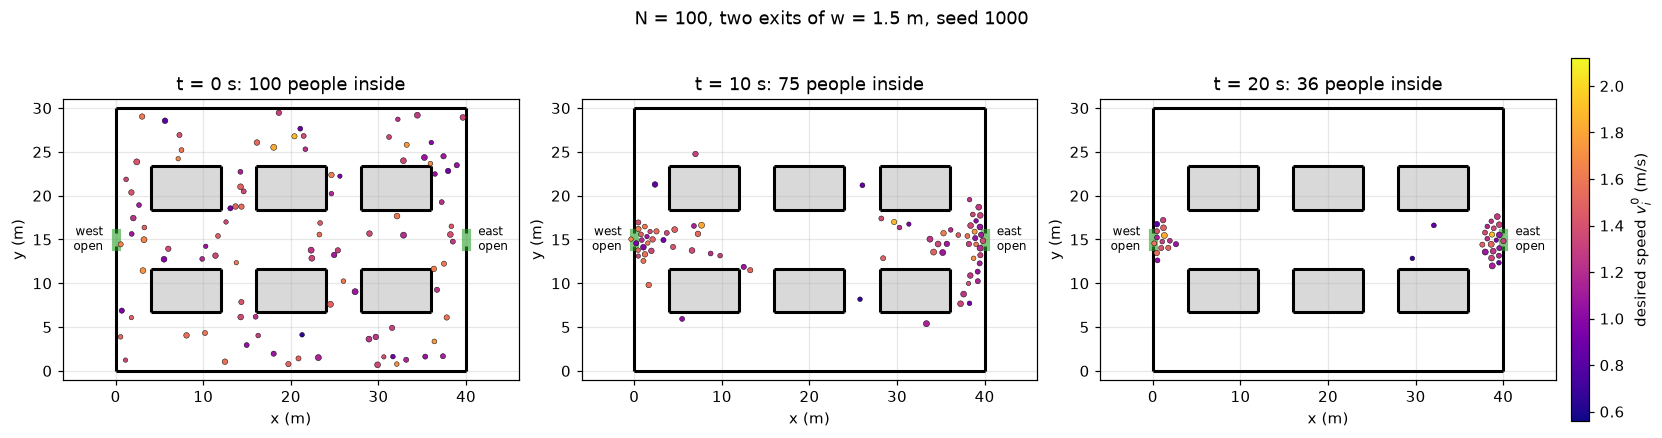

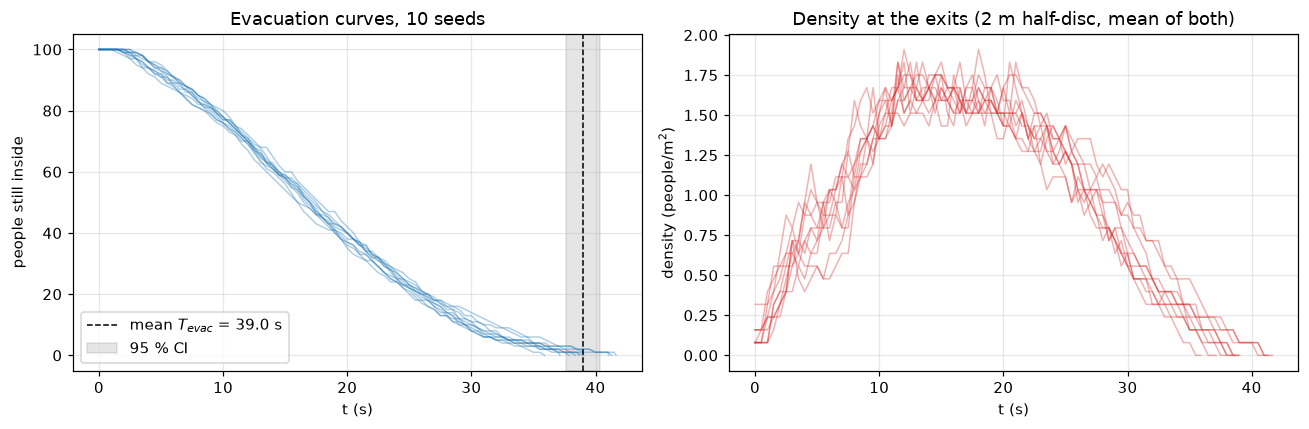

In [15]:
# Figures: crowd snapshots for the first seed, and the evacuation curves of all seeds.
from matplotlib.collections import EllipseCollection

_run = mvp_runs[0]
fig, axes = plt.subplots(1, len(SNAP_TIMES), figsize=(15, 4.0), layout="constrained")
for ax, t, pos in zip(axes, _run.snap_times, _run.snaps):
    plot_mall(get_mall(MVP_W)[0], ax=ax, title=f"t = {t:g} s: {np.isfinite(pos[:, 0]).sum()} people inside")
    inside = np.isfinite(pos[:, 0])
    discs = EllipseCollection(2 * _run.r[inside], 2 * _run.r[inside], 0, units="xy", offsets=pos[inside],
                              offset_transform=ax.transData, array=_run.v0[inside], cmap="plasma",
                              clim=(V0_MEAN - 3 * V0_SD, V0_MEAN + 3 * V0_SD), zorder=5, edgecolor="k", lw=0.3)
    ax.add_collection(discs)
fig.colorbar(discs, ax=axes, shrink=0.9, pad=0.01, label="desired speed $v_i^0$ (m/s)")
fig.suptitle(f"N = {MVP_N}, two exits of w = {MVP_W} m, seed {_run.seed}")
fig.savefig(FIG_DIR / "mvp_snapshots.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for r in mvp_runs:
    axes[0].plot(r.t_rec, MVP_N - r.n_out_rec.sum(axis=1), color="tab:blue", alpha=0.35, lw=1)
    axes[1].plot(r.t_rec, r.density_rec.mean(axis=1), color="tab:red", alpha=0.35, lw=1)
axes[0].axvline(_m, color="k", ls="--", lw=1, label=f"mean $T_{{evac}}$ = {_m:.1f} s")
axes[0].axvspan(_m - _h, _m + _h, color="k", alpha=0.1, label="95 % CI")
axes[0].set(xlabel="t (s)", ylabel="people still inside", title=f"Evacuation curves, {MVP_R} seeds")
axes[0].legend()
axes[1].set(xlabel="t (s)", ylabel="density (people/m$^2$)",
            title=f"Density at the exits ({DENSITY_RADIUS:g} m half-disc, mean of both)")
fig.tight_layout()
fig.savefig(FIG_DIR / "mvp_evacuation_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Discussion and limitations

[What the results mean for the real-world question; the most important assumptions and their effect; what you would do next.]

**Web demo reference value:** with default settings the web demo should reproduce [value ± tolerance] from section [N].

## 7. References

IEEE style. The numbers match the citations in Section 2. The same list, with a note on what each source is used for, is in `REFERENCES.md`.

1. D. Helbing and P. Molnár, "Social force model for pedestrian dynamics," *Phys. Rev. E*, vol. 51, no. 5, pp. 4282–4286, 1995, doi: [10.1103/PhysRevE.51.4282](https://doi.org/10.1103/PhysRevE.51.4282).
2. D. Helbing, I. Farkas and T. Vicsek, "Simulating dynamical features of escape panic," *Nature*, vol. 407, pp. 487–490, 2000, doi: [10.1038/35035023](https://doi.org/10.1038/35035023).
3. L. Verlet, "Computer 'experiments' on classical fluids. I. Thermodynamical properties of Lennard-Jones molecules," *Phys. Rev.*, vol. 159, no. 1, pp. 98–103, 1967, doi: [10.1103/PhysRev.159.98](https://doi.org/10.1103/PhysRev.159.98).
4. W. C. Swope, H. C. Andersen, P. H. Berens and K. R. Wilson, "A computer simulation method for the calculation of equilibrium constants for the formation of physical clusters of molecules: Application to small water clusters," *J. Chem. Phys.*, vol. 76, no. 1, pp. 637–649, 1982, doi: [10.1063/1.442716](https://doi.org/10.1063/1.442716).
5. M. P. Allen and D. J. Tildesley, *Computer Simulation of Liquids*, 2nd ed. Oxford, U.K.: Oxford Univ. Press, 2017.
6. E. W. Dijkstra, "A note on two problems in connexion with graphs," *Numer. Math.*, vol. 1, pp. 269–271, 1959, doi: [10.1007/BF01386390](https://doi.org/10.1007/BF01386390).
7. A. Seyfried, O. Passon, B. Steffen, M. Boltes, T. Rupprecht and W. Klingsch, "New insights into pedestrian flow through bottlenecks," *Transp. Sci.*, vol. 43, no. 3, pp. 395–406, 2009, doi: [10.1287/trsc.1090.0263](https://doi.org/10.1287/trsc.1090.0263).
8. T. Kretz, A. Grünebohm and M. Schreckenberg, "Experimental study of pedestrian flow through a bottleneck," *J. Stat. Mech.*, vol. 2006, no. 10, Art. no. P10014, 2006, doi: [10.1088/1742-5468/2006/10/P10014](https://doi.org/10.1088/1742-5468/2006/10/P10014).
9. A. M. Law, *Simulation Modeling and Analysis*, 5th ed. New York, NY, USA: McGraw-Hill, 2015.
10. J. A. Sethian, "A fast marching level set method for monotonically advancing fronts," *Proc. Natl. Acad. Sci. USA*, vol. 93, no. 4, pp. 1591–1595, 1996, doi: [10.1073/pnas.93.4.1591](https://doi.org/10.1073/pnas.93.4.1591).